In [1]:
import os
import sys
from pathlib import Path

# Sube hasta la raíz del proyecto (la carpeta con requirements.txt)
raiz = Path.cwd()
for _ in range(5):
    if (raiz / 'requirements.txt').exists():
        break
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, 'src')
print('Trabajando en:', raiz)

Trabajando en: /Users/alvaroruiz/Desktop/proyecto f1/f1-strategy-analytics


# Fase 4: predicción de podios

**Pregunta:** ¿podemos predecir, *antes de la carrera*, qué pilotos acabarán en el podio?

Es un problema de **clasificación binaria**: para cada fila (un piloto en una carrera)
queremos predecir `Podio = 1` si acabó entre los 3 primeros y `0` si no.

| Día | Contenido |
|---|---|
| 21 | Ingeniería de variables |
| 22 | División temporal y data leakage |
| 23 | Regresión logística y modelo trivial |
| 24 | Random Forest y Gradient Boosting |
| 25 | Interpretación y análisis de errores |
| 26 | Guardar el modelo y exportar predicciones |

---
## Día 21 · Ingeniería de variables

Datos: resultados y clasificaciones 2018-2026 de la API de Jolpica
(`src/extract_history.py`). Solo incluyen carreras **ya disputadas**.
El código de las variables vive en `src/features.py` para poder reutilizarlo
en el pipeline y en los tests.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import features as ft

resultados = pd.read_parquet('data/raw/history_results.parquet')
quali = pd.read_parquet('data/raw/history_quali.parquet')

print(f'Resultados: {len(resultados)} filas · {resultados.groupby(["Year", "Round"]).ngroups} carreras')
print(f'Clasificación: {len(quali)} filas')
resultados.groupby('Year').agg(carreras=('Round', 'nunique'), filas=('Round', 'size'))

Resultados: 3832 filas · 190 carreras
Clasificación: 3824 filas


,carreras,filas
Year,,
2018,21,420
2019,21,420
2020,17,340
2021,22,440
2022,22,440
2023,22,440
2024,24,479
2025,24,479
2026,17,374


### Las variables

Todas se calculan en `features.construir_variables()` con una regla: **solo información
anterior a la carrera**.

| Variable | Qué mide | Cómo se evita mirar al futuro |
|---|---|---|
| `GridAdj` | Posición de salida (el pit lane, `Grid = 0`, cuenta como 20) | La parrilla se conoce antes de la salida |
| `PuntosPilotoAntes` | Puntos del piloto en la temporada | Acumulado menos los puntos de la propia carrera |
| `PuntosEquipoAntes` | Puntos del equipo en la temporada | Igual, sumando los dos pilotos |
| `MediaUlt3` | Media de la posición final en las 3 carreras previas | `shift(1)` y luego media móvil |
| `PosCircuitoPrevia` | Posición la última vez que corrió en ese circuito | `shift(1)` dentro de (piloto, circuito) |
| `DifPolePct` | % de diferencia con la pole en clasificación | La clasificación es el día anterior |

**`shift(1)` es la clave:** desplaza la columna una fila hacia abajo dentro de cada grupo,
así cada carrera ve el valor de la anterior y nunca el suyo. Si calculásemos la media de las
últimas 3 carreras *incluyendo la actual*, el modelo vería parte de la respuesta.

In [3]:
datos = ft.cargar_datos()
datos[['Year', 'Round', 'Event', 'Abbreviation', 'TeamName', 'Position', ft.TARGET] + ft.FEATURES].head(10)

,Year,Round,Event,Abbreviation,TeamName,Position,Podio,GridAdj,PuntosPilotoAntes,PuntosEquipoAntes,MediaUlt3,PosCircuitoPrevia,DifPolePct
0,2018,1,Australian Grand Prix,VET,Ferrari,1,1,3,0.0,0.0,NaN,NaN,0.830417
1,2018,1,Australian Grand Prix,HAM,Mercedes,2,1,1,0.0,0.0,NaN,NaN,0.000000
2,2018,1,Australian Grand Prix,RAI,Ferrari,3,1,2,0.0,0.0,NaN,NaN,0.818097
3,2018,1,Australian Grand Prix,RIC,Red Bull,4,0,8,0.0,0.0,NaN,NaN,1.217288
4,2018,1,Australian Grand Prix,ALO,McLaren,5,0,10,0.0,0.0,NaN,NaN,2.997634
5,2018,1,Australian Grand Prix,VER,Red Bull,6,0,4,0.0,0.0,NaN,NaN,0.880932
6,2018,1,Australian Grand Prix,HUL,Renault,7,0,7,0.0,0.0,NaN,NaN,2.917550
7,2018,1,Australian Grand Prix,BOT,Mercedes,8,0,15,0.0,0.0,NaN,NaN,1.139668
8,2018,1,Australian Grand Prix,VAN,McLaren,9,0,11,0.0,0.0,NaN,NaN,3.313045
9,2018,1,Australian Grand Prix,SAI,Renault,10,0,9,0.0,0.0,NaN,NaN,2.337243


### Un ejemplo para ver el `shift(1)` en acción

Verstappen en 2024: `PuntosPilotoAntes` en cada ronda es la suma de los puntos de las
rondas **anteriores**. En la ronda 1 vale 0 y en la ronda 2 vale lo que sacó en la 1.

In [4]:
ver = datos[(datos['Year'] == 2024) & (datos['Abbreviation'] == 'VER')]
ver[['Round', 'Event', 'Position', 'Points', 'PuntosPilotoAntes', 'MediaUlt3', 'PosCircuitoPrevia']].head(6)

,Round,Event,Position,Points,PuntosPilotoAntes,MediaUlt3,PosCircuitoPrevia
2500,1,Bahrain Grand Prix,1,26.0,0.0,1.0,1.0
2520,2,Saudi Arabian Grand Prix,1,25.0,26.0,1.0,2.0
2558,3,Australian Grand Prix,19,0.0,51.0,1.0,1.0
2559,4,Japanese Grand Prix,1,26.0,51.0,7.0,1.0
2579,5,Chinese Grand Prix,1,25.0,77.0,7.0,4.0
2600,6,Miami Grand Prix,2,18.0,102.0,7.0,1.0


Fíjate en `MediaUlt3` de la ronda 1 de 2024: usa las últimas carreras de **2023**
(la media continúa entre temporadas) y nunca la carrera de Baréin 2024 que está describiendo.
`PosCircuitoPrevia` es la posición en el mismo circuito la última vez que corrió allí.

### Prueba de que no hay fuga de información

Test empírico: **falseo el resultado de una carrera** (reordeno las posiciones y le pongo
50 puntos a todos) y recalculo las variables. Si el código es correcto, solo pueden cambiar las
variables de las carreras *posteriores*; las de esa carrera y las anteriores deben quedar idénticas.

In [5]:
r2 = resultados.copy()
mascara = (r2['Year'] == 2024) & (r2['Round'] == 10)
r2.loc[mascara, 'Position'] = r2.loc[mascara, 'Position'].sample(frac=1, random_state=0).values
r2.loc[mascara, 'Points'] = 50
alterado = ft.construir_variables(r2, quali)

clave = ['Year', 'Round', 'DriverId']
a = datos.set_index(clave)[ft.FEATURES]
b = alterado.set_index(clave)[ft.FEATURES].loc[a.index]
cambiaron = ~((a == b) | (a.isna() & b.isna())).all(axis=1)

primera = min((y, r) for y, r, _ in a.index[cambiaron.values])
print(f'Filas cuyas variables cambian: {cambiaron.sum()}')
print(f'Primera carrera afectada: año {primera[0]}, ronda {primera[1]}  (alteré la ronda 10)')
assert primera > (2024, 10), '¡Fuga de información!'

Filas cuyas variables cambian: 294
Primera carrera afectada: año 2024, ronda 11  (alteré la ronda 10)


✅ La primera carrera afectada es la 11: nada de lo anterior (ni la propia ronda 10) cambia.

### Valores perdidos

- `PosCircuitoPrevia` falta ~30 % de las veces: debutantes o circuitos nuevos (p. ej. Miami, Las Vegas).
- `MediaUlt3` falta en la primera carrera de cada piloto.
- `DifPolePct` falta cuando el piloto no marcó tiempo en clasificación.

**No los relleno aquí.** Imputar con la mediana usando *todos* los datos sería ya una forma sutil de
data leakage; lo haré dentro del `Pipeline` del modelo, ajustando el imputador solo con el entrenamiento.

In [6]:
datos[ft.FEATURES].isna().mean().mul(100).round(1).rename('% perdidos').to_frame()

,% perdidos
GridAdj,0.0
PuntosPilotoAntes,0.0
PuntosEquipoAntes,0.0
MediaUlt3,1.1
PosCircuitoPrevia,29.6
DifPolePct,1.9


### Exploración: ¿qué relación tiene cada variable con el podio?

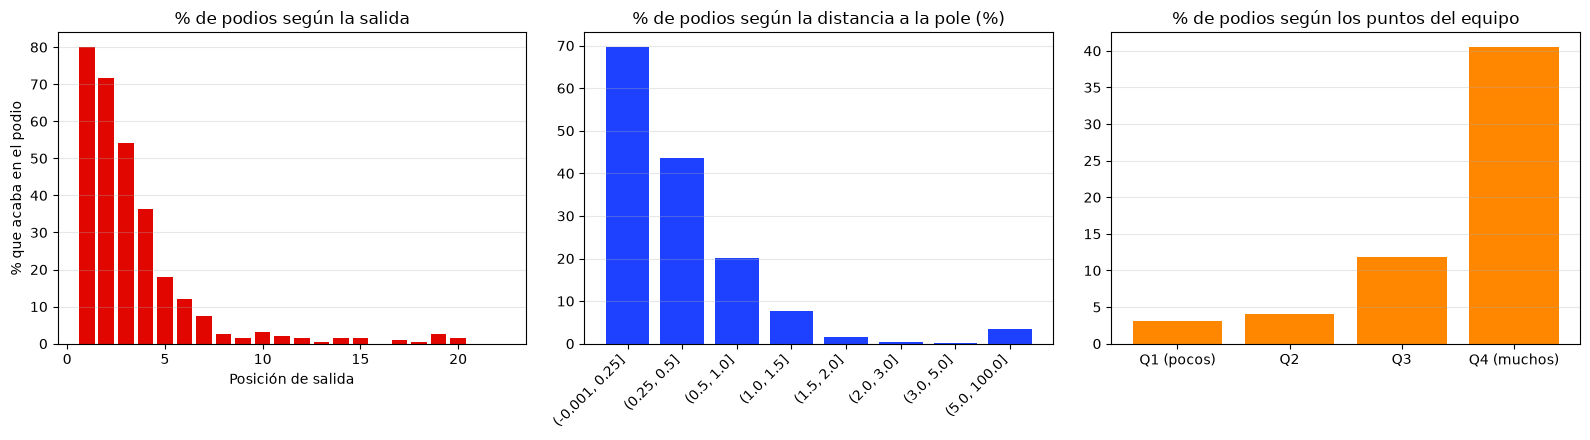

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) Tasa de podio según la posición de salida
tasa = datos.groupby('GridAdj')[ft.TARGET].mean()
axes[0].bar(tasa.index, tasa.values * 100, color='#E10600')
axes[0].set_title('% de podios según la salida')
axes[0].set_xlabel('Posición de salida')
axes[0].set_ylabel('% que acaba en el podio')

# 2) Tasa de podio según el % de diferencia con la pole (por tramos)
tramos = pd.cut(datos['DifPolePct'], [0, 0.25, 0.5, 1, 1.5, 2, 3, 5, 100], include_lowest=True)
t2 = datos.groupby(tramos, observed=True)[ft.TARGET].mean() * 100
axes[1].bar(range(len(t2)), t2.values, color='#1E41FF')
axes[1].set_xticks(range(len(t2)), [str(i) for i in t2.index], rotation=45, ha='right')
axes[1].set_title('% de podios según la distancia a la pole (%)')

# 3) Podios según puntos del equipo antes de la carrera (cuartiles)
cuartil = pd.qcut(datos['PuntosEquipoAntes'].rank(method='first'), 4, labels=['Q1 (pocos)', 'Q2', 'Q3', 'Q4 (muchos)'])
t3 = datos.groupby(cuartil, observed=True)[ft.TARGET].mean() * 100
axes[2].bar(t3.index.astype(str), t3.values, color='#FF8700')
axes[2].set_title('% de podios según los puntos del equipo')

for ax in axes:
    ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Conclusiones del día 21

- Solo ~15 % de las filas son podio (3 de ~20 pilotos): las clases están **desbalanceadas**, así que la
  exactitud (*accuracy*) engañará; usaremos recall, F1 y AUC.
- Salir de las 3 primeras posiciones es el factor más fuerte, pero no perfecto: de ahí que haya algo que modelar
  (estrategia, fiabilidad, salidas, safety cars...).
- La distancia a la pole y los puntos del equipo capturan **el ritmo del coche**, que la parrilla sola no recoge.
- Todas las variables pasan la prueba de invarianza: no usan información futura.

**Supuestos y limitaciones de las variables**
- `Grid = 0` se trata como 20 aunque en 2026 hay 22 coches.
- Los puntos son solo de carrera: no incluyen los puntos de las *sprints* (Jolpica los separa).
- `Position` incluye a los abandonos al final de la clasificación, así que un DNF empeora `MediaUlt3`.
- `DifPolePct` compara la mejor vuelta de cada piloto en Q1/Q2/Q3; quien cae en Q1 sale perjudicado por la evolución de la pista.
- Cambios de reglamento (2022, 2026) rompen la comparabilidad de ritmos entre temporadas.

In [8]:
datos.to_parquet('data/processed/features_podio.parquet')
print('Guardado data/processed/features_podio.parquet')

Guardado data/processed/features_podio.parquet


---
## Día 22 · Evitar el data leakage

### ¿Qué es el data leakage?

El **data leakage** (fuga de datos) ocurre cuando el modelo, durante el entrenamiento, tiene
acceso a información que **no tendría en el momento real de predecir**. El resultado es un modelo
que en el notebook parece magnífico (métricas casi perfectas) y que en producción falla, porque
la "ayuda" que recibía ya no está.

Analogía: es como hacer un examen con las respuestas en la mano. La nota es altísima, pero no
demuestra que sepas la materia.

**Tres formas de fuga que podrían darse en este proyecto:**

1. **Fuga del objetivo (*target leakage*).** Una variable contiene, directa o indirectamente, la respuesta.
   Ejemplo: usar los puntos acumulados *incluyendo la carrera que queremos predecir*, o la "media de las últimas
   3 posiciones" contando la carrera actual. Si ganó, esos puntos ya incluyen el podio. Por eso en `features.py` todo
   lleva `shift(1)`.
2. **Fuga temporal.** Mezclar carreras al azar en entrenamiento y test. El modelo entrenaría con carreras de 2025 para
   "predecir" una de 2024: usa el futuro para predecir el pasado. En series temporales, **el test siempre va después del entrenamiento**.
3. **Fuga por preprocesado.** Ajustar el `StandardScaler` o el imputador con *todos* los datos antes de dividir:
   la media y la mediana del test se "cuelan" en el entrenamiento. Solución: meter el preprocesado en un `Pipeline`
   y ajustarlo solo con el conjunto de entrenamiento (`fit` en train, `transform` en el resto).

**Si alguna vez sale un AUC de 0,99 en un problema tan incierto como la F1, desconfía antes de celebrar.**

### La división de este proyecto

| Conjunto | Temporadas | Para qué |
|---|---|---|
| Entrenamiento | 2018-2023 | Ajustar los modelos |
| Validación | 2024 | Elegir modelo e hiperparámetros |
| Test | 2025 | Medida final e imparcial: se mira **una sola vez** |
| "En vivo" | 2026 | Predicciones de la temporada en curso, sin tocarlas para entrenar |

In [9]:
train, val, test, vivo = ft.dividir_temporal(datos)

resumen = pd.DataFrame({
    'Temporadas': ['2018-2023', '2024', '2025', '2026 (hasta Singapur)'],
    'Carreras': [d.groupby(['Year', 'Round']).ngroups for d in (train, val, test, vivo)],
    'Filas': [len(d) for d in (train, val, test, vivo)],
    '% podios': [round(d[ft.TARGET].mean() * 100, 1) for d in (train, val, test, vivo)],
}, index=['Entrenamiento', 'Validación', 'Test', 'En vivo'])
resumen

,Temporadas,Carreras,Filas,% podios
Entrenamiento,2018-2023,125,2500,15.0
Validación,2024,24,479,15.0
Test,2025,24,479,15.0
En vivo,2026 (hasta Singapur),17,374,13.6


La proporción de podios es ~14-15 % en todos los conjuntos, como esperábamos
(3 podios de 20-22 coches). Al ser tan similar, cualquier diferencia de métricas vendrá del modelo y no de un
reparto de clases distinto.

### Demostración: cómo se ve una fuga

Voy a entrenar el mismo modelo sencillo (regresión logística) de cuatro maneras y compararlas en validación (2024):

1. **Honesta:** variables correctas + división temporal.
2. **Fuga de objetivo:** añado `Points`, los puntos que suma el piloto *en esa carrera*. Es el error clásico: una columna de
   la tabla de resultados que se queda en la matriz de variables sin darnos cuenta.
3. **Fuga de futuro:** añado la media de posiciones de la temporada **completa** (incluye carreras posteriores a la que se predice).
4. **Mezcla aleatoria:** variables correctas, pero dividiendo al azar y mezclando 2018-2024.

Todas usan el mismo `Pipeline` (imputación + escalado + regresión logística), que ajusta el preprocesado solo con lo que ve en `fit`.

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def modelo_simple():
    return Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler()),
        ('logit', LogisticRegression(max_iter=1000, class_weight='balanced')),
    ])


def auc(modelo, X, y):
    return roc_auc_score(y, modelo.predict_proba(X)[:, 1])


# 1) Honesta
m = modelo_simple().fit(train[ft.FEATURES], train[ft.TARGET])
auc_honesta = auc(m, val[ft.FEATURES], val[ft.TARGET])

# 2) Fuga de objetivo: los puntos de la propia carrera
con_fuga = datos.copy()
vars_f1 = ft.FEATURES + ['Points']
tr_f, va_f, _, _ = ft.dividir_temporal(con_fuga)
m2 = modelo_simple().fit(tr_f[vars_f1], tr_f[ft.TARGET])
auc_fuga = auc(m2, va_f[vars_f1], va_f[ft.TARGET])

# 3) Fuga de futuro: media de posiciones de TODA la temporada (incluye carreras futuras)
con_fuga['MediaTemporadaCompleta'] = con_fuga.groupby(['Year', 'DriverId'])['Position'].transform('mean')
vars_f2 = ft.FEATURES + ['MediaTemporadaCompleta']
tr_g, va_g, _, _ = ft.dividir_temporal(con_fuga)
m3 = modelo_simple().fit(tr_g[vars_f2], tr_g[ft.TARGET])
auc_futuro = auc(m3, va_g[vars_f2], va_g[ft.TARGET])

# 4) Mezcla aleatoria: mezcla al azar 2018-2024
hasta_2024 = datos[datos['Year'] <= 2024]
a, b = train_test_split(hasta_2024, test_size=0.2, random_state=0, shuffle=True)
m4 = modelo_simple().fit(a[ft.FEATURES], a[ft.TARGET])
auc_azar = auc(m4, b[ft.FEATURES], b[ft.TARGET])

pd.DataFrame({
    'AUC-ROC': [auc_honesta, auc_fuga, auc_futuro, auc_azar],
    'Comentario': ['Referencia realista',
                   'Fuga clara: la columna contiene la respuesta',
                   'Fuga sutil: usa carreras futuras de la misma temporada',
                   'Ve carreras futuras al entrenar'],
}, index=['1. Honesta (temporal)', '2. Fuga de objetivo', '3. Fuga de futuro', '4. Mezcla aleatoria']).round(3)

,AUC-ROC,Comentario
1. Honesta (temporal),0.918,Referencia realista
2. Fuga de objetivo,1.000,Fuga clara: la columna contiene la respuesta
3. Fuga de futuro,0.926,Fuga sutil: usa carreras futuras de la misma t...
4. Mezcla aleatoria,0.917,Ve carreras futuras al entrenar


### Lectura

- La **fuga de objetivo** (la fila 2) dispara el AUC hasta casi 1: quien suma 25, 18 o 15 puntos en la carrera
  está en el podio, y el modelo solo tiene que leerlo. Un número así sería irreal, porque antes de la carrera esos puntos no existen.
- La **fuga de futuro** (fila 3) y la **mezcla aleatoria** (fila 4) apenas mueven la métrica en este problema. No es que no
  sean fugas: es que un agregado de ~22 carreras apenas depende de *una* de ellas, y nuestro modelo lineal casi no puede
  memorizar carreras vecinas. **Que una fuga sea pequeña hoy no la hace aceptable**: con un Random Forest, o con variables más
  próximas a la carrera, el efecto crecería. Y en cualquier caso la métrica deja de ser representativa de lo que pasará en la próxima carrera real.
- Lección: una fuga solo se nota en las métricas cuando la variable delata *esa* fila. Las sutiles hay que cazarlas
  **revisando el código** (por eso la prueba de invarianza del día 21) y no esperando a que el AUC se dispare.

**Regla práctica:** si una métrica parece demasiado buena, busca qué variable usa información del futuro;
y si parece normal, comprueba igualmente que cada variable se podría haber calculado el día antes de la carrera.

### Qué vamos a hacer a partir de ahora
- Todo el preprocesado (imputar, escalar) vivirá dentro de un `Pipeline`.
- Los hiperparámetros se elegirán con validación **temporal** (`TimeSeriesSplit` el día 24), nunca con `KFold` aleatorio.
- El conjunto de **test (2025) no se toca** hasta el final: se mira una vez, con el modelo ya elegido.
- 2026 solo se usa para generar predicciones.

---
## Día 23 · Regresión logística

La **regresión logística** modela la probabilidad de podio como
`P(podio) = 1 / (1 + e^-(b0 + b1·x1 + b2·x2 + ...))`.
Es lineal en el *log-odds*, lo que la hace muy interpretable: es el equivalente de `glm(family = binomial)` en R.

Construimos un `Pipeline` (código en `src/model.py`):
1. `SimpleImputer(median)`: rellena los vacíos con la mediana **del entrenamiento**.
2. `StandardScaler`: media 0 y desviación 1 (necesario para comparar coeficientes y para la regularización).
3. `LogisticRegression(class_weight='balanced')`: como solo ~15 % de las filas son podio, `balanced` pondera cada clase
   de forma inversa a su frecuencia para que el modelo no se conforme con decir siempre "no podio".

**Regla de oro:** todos los modelos se comparan en **validación (2024)**. El test (2025) se reserva para el final.

In [11]:
import model as md

X_train, y_train = train[ft.FEATURES], train[ft.TARGET]
X_val, y_val = val[ft.FEATURES], val[ft.TARGET]

logit = md.pipeline_logistico().fit(X_train, y_train)
proba_logit = logit.predict_proba(X_val)[:, 1]

print('Entrenado con', len(X_train), 'filas (2018-2023). Evaluando en', len(X_val), 'filas (2024).')

Entrenado con 2500 filas (2018-2023). Evaluando en 479 filas (2024).


### Matriz de confusión (umbral 0,5)

Filas = realidad, columnas = predicción. Con `class_weight='balanced'` el umbral 0,5 es muy "generoso" con la clase podio.

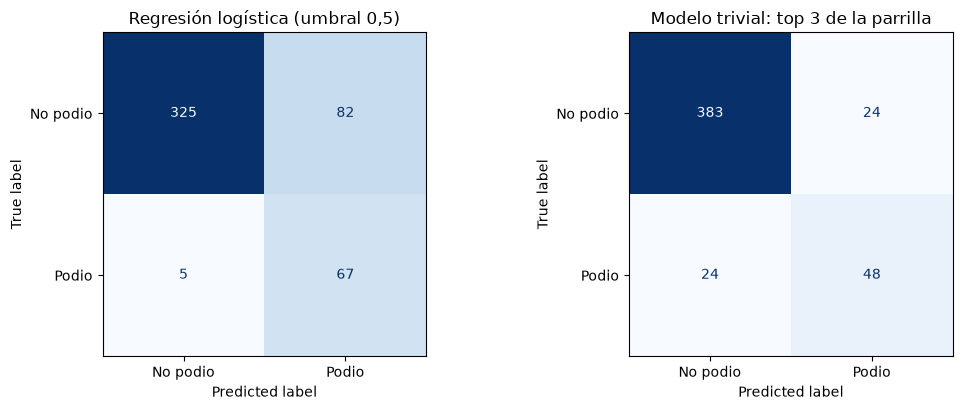

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm1 = md.matriz_confusion(y_val, proba_logit)
cm2 = md.matriz_confusion(y_val, md.pred_trivial_parrilla(val), umbral=0.5)
for ax, cm, titulo in [(axes[0], cm1, 'Regresión logística (umbral 0,5)'),
                       (axes[1], cm2, 'Modelo trivial: top 3 de la parrilla')]:
    ConfusionMatrixDisplay(cm.values, display_labels=['No podio', 'Podio']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

### Métricas y comparación con el modelo trivial

El **modelo trivial** dice "los 3 primeros de la parrilla hacen podio". No aprende nada, pero es la vara de medir:
si un modelo complejo no lo supera, no aporta valor.

- **Precisión:** de los que predigo podio, ¿cuántos lo son? (falsas alarmas)
- **Recall:** de los podios reales, ¿cuántos detecto? (podios que se me escapan)
- **F1:** media armónica de ambos.
- **AUC-ROC:** capacidad de *ordenar* (¿pone más probabilidad a quien acaba en podio?). No depende del umbral.
- **Accuracy:** engañosa aquí: un modelo que dijera siempre "no podio" tendría ~85 %.

Comparo tres formas de decidir: umbral 0,5; **top-3 por carrera** (los 3 con más probabilidad de cada GP, que encaja con el hecho de que
siempre hay 3 podios) y el trivial.

In [13]:
comparacion = pd.DataFrame({
    'Logística (umbral 0,5)': md.metricas(y_val, proba_logit),
    'Logística (top 3 por carrera)': md.metricas_top3(y_val, val, proba_logit),
    'Trivial (top 3 parrilla)': md.metricas_trivial(y_val, val),
}).T.round(3)
comparacion

,Accuracy,Precisión,Recall,F1,AUC-ROC
"Logística (umbral 0,5)",0.818,0.450,0.931,0.606,0.918
Logística (top 3 por carrera),0.896,0.653,0.653,0.653,0.918
Trivial (top 3 parrilla),0.900,0.667,0.667,0.667,0.921


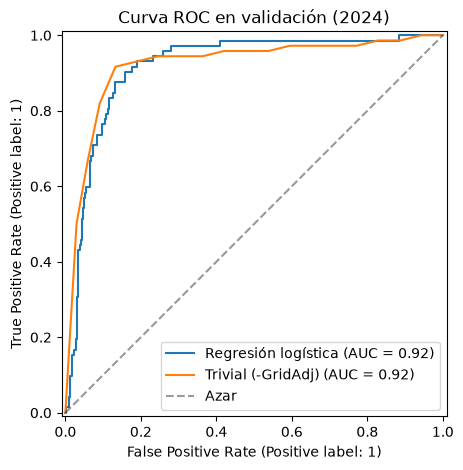

In [14]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_val, proba_logit, name='Regresión logística', ax=ax)
RocCurveDisplay.from_predictions(y_val, -val['GridAdj'], name='Trivial (-GridAdj)', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Azar')
ax.set_title('Curva ROC en validación (2024)')
ax.legend()
plt.show()

### ¿Qué dicen estos números?

- **El umbral 0,5 con `balanced` detecta casi todos los podios (recall ≈ 93 %) a costa de muchas falsas alarmas
  (precisión ≈ 45 %).** Es un compromiso, no un fallo: `class_weight='balanced'` empuja las probabilidades hacia arriba.
- **Cuando se fuerza a elegir exactamente 3 por carrera, la logística acierta ≈ 65 % de los podios, y el modelo trivial ≈ 67 %.**
  Los dos son prácticamente iguales, y el AUC también (0,918 frente a 0,921).
- **Conclusión honesta: con estas variables, la regresión logística no mejora el simple "los 3 primeros de la parrilla"**.
  La salida ya contiene casi toda la información predictiva. El resto es lo que ocurre en carrera: estrategia, safety cars, fallos
  mecánicos, adelantamientos. Eso es difícil de anticipar con datos previos y fija un techo para cualquier modelo.
- En el día 24 comprobaremos si un modelo no lineal exprime algo más (interacciones entre variables).

### Interpretar los coeficientes (como en R con `caret`)

En R harías algo así:
```r
modelo <- train(Podio ~ ., data = train, method = "glm", family = "binomial",
                preProcess = c("center", "scale"))
summary(modelo)      # coeficientes, errores estándar, p-valores
exp(coef(modelo$finalModel))   # odds ratios
varImp(modelo)       # importancia
confusionMatrix(pred, obs, positive = "1")
```
Aquí `scikit-learn` no da p-valores, así que calculo los **coeficientes**, los **odds ratios** (`exp(coef)`) y
**intervalos de confianza por bootstrap** (remuestreo con reemplazo 300 veces).

- **Coef (std):** cambio en el log-odds de podio por cada +1 desviación típica de la variable.
- **Odds ratio (std):** `exp(coef)`. Un 0,24 significa que cada +1 desviación en esa variable *multiplica por 0,24* las odds de podio.
- **Odds ratio (unidad):** lo mismo por +1 unidad real (por ejemplo, salir una posición más atrás).

In [15]:
coefs = md.tabla_coeficientes(logit, ft.FEATURES)
ic = md.bootstrap_coeficientes(X_train, y_train, n=300)
tabla = coefs.join(ic).round(3)
tabla['¿IC incluye 0?'] = (tabla['IC 2.5 %'] <= 0) & (tabla['IC 97.5 %'] >= 0)
tabla

,Coef (std),Odds ratio (std),Odds ratio (unidad),IC 2.5 %,IC 97.5 %,¿IC incluye 0?
GridAdj,-1.446,0.235,0.779,-2.209,-0.876,False
DifPolePct,-0.868,0.420,0.689,-2.857,0.273,True
MediaUlt3,-0.585,0.557,0.877,-0.767,-0.383,False
PuntosPilotoAntes,0.437,1.548,1.006,-0.015,0.979,True
PosCircuitoPrevia,-0.109,0.897,0.977,-0.269,0.039,True
PuntosEquipoAntes,-0.018,0.983,1.000,-0.520,0.465,True


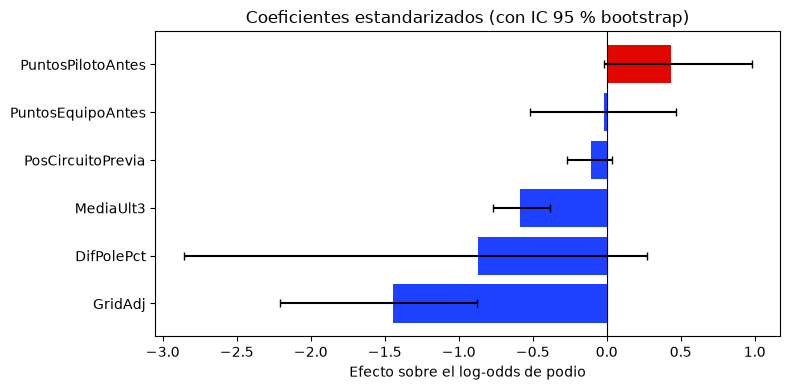

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
t = tabla.sort_values('Coef (std)')
ax.barh(t.index, t['Coef (std)'], color=np.where(t['Coef (std)'] < 0, '#1E41FF', '#E10600'),
        xerr=[t['Coef (std)'] - t['IC 2.5 %'], t['IC 97.5 %'] - t['Coef (std)']], capsize=3)
ax.axvline(0, color='k', lw=0.8)
ax.set_title('Coeficientes estandarizados (con IC 95 % bootstrap)')
ax.set_xlabel('Efecto sobre el log-odds de podio')
plt.tight_layout()
plt.show()

### Interpretación

- **`GridAdj` (≈ -1,45)** es el efecto dominante: cada +1 desviación (≈ 5,8 posiciones) en la parrilla **divide por ~4** las odds de podio.
  Por posición, las odds se multiplican por ≈ 0,78: salir una plaza más atrás quita un ~22 % de odds. El IC no incluye 0: es robusto.
- **`DifPolePct` (≈ -0,87)** y **`MediaUlt3` (≈ -0,59)** también restan: estar lejos de la pole y haber acabado mal las últimas carreras baja las odds, incluso
  a igualdad de parrilla (ritmo y forma). `MediaUlt3` es significativa; `DifPolePct` tiene un IC muy ancho, porque unas pocas clasificaciones atípicas (diferencias de hasta 45 %) pesan mucho.
- **`PuntosPilotoAntes` (+0,44) y `PuntosEquipoAntes` (≈ 0)**: ¡cuidado! Están **fuertemente correlacionadas (r ≈ 0,95)**. Es **multicolinealidad**: el modelo no
  puede separar sus efectos y reparte el peso casi todo en una, de forma inestable (los IC incluyen 0). No hay que interpretar "los puntos del equipo no importan":
  solo que, una vez conocidos los del piloto, añaden poco. Para *predecir* no es grave; para *interpretar* sí.
- **`PosCircuitoPrevia` (≈ -0,11)** casi no aporta: el historial en el circuito dice poco una vez conocida la forma actual.

**Supuestos y limitaciones de la regresión logística**
- Supone una relación lineal en el log-odds y ninguna interacción (p. ej. que salir 2º vale lo mismo en cualquier equipo).
- Los IC por bootstrap tratan cada fila como independiente, pero las filas de una misma carrera comparten coche, clima y safety car; son optimistas.
- Con `class_weight='balanced'` las probabilidades **no están calibradas** (sobreestiman): sirven para ordenar, no como probabilidad real.
- Las temporadas son distintas (cambios de reglamento en 2022 y 2026), así que el modelo asume que las relaciones se mantienen estables.

---
## Día 24 · Modelos más potentes: Random Forest y Gradient Boosting

La regresión logística solo capta relaciones **lineales**. Los modelos de árboles pueden captar **interacciones y umbrales**
(por ejemplo, "salir 2º importa mucho en un equipo puntero y poco en uno que no puntúa").

- **Random Forest:** muchos árboles profundos entrenados *en paralelo* con muestras aleatorias de filas y variables; se promedian.
  Reduce la varianza (el sobreajuste de un solo árbol).
- **`HistGradientBoostingClassifier`:** árboles pequeños entrenados *en secuencia*, cada uno corrigiendo los errores del anterior.
  Es el equivalente en scikit-learn a XGBoost/LightGBM, y gestiona NaN de forma nativa.

### Cómo elegimos los hiperparámetros sin trampa

- **`RandomizedSearchCV`:** en vez de probar todas las combinaciones (`GridSearchCV`, carísimo), sortea 40 combinaciones al azar de un espacio de búsqueda.
- **`TimeSeriesSplit`:** la validación cruzada normal (`KFold`) mezclaría pasado y futuro. Aquí cada *fold* entrena con las carreras anteriores y valida con las posteriores
  (ventana creciente). Lo aplico sobre la **lista de carreras** (`model.cortes_temporales`) para que ninguna carrera quede partida a medias.
- La búsqueda usa **solo 2018-2023**. La validación 2024 y el test 2025 no se tocan para elegir hiperparámetros.
- Métrica de la búsqueda: **AUC-ROC**, que no depende del umbral de decisión.

In [17]:
cortes = md.cortes_temporales(train)
resumen_folds = pd.DataFrame(
    [{'Fold': i + 1,
      'Entrena con': f'{len(a)} filas hasta {train.iloc[a].Year.iloc[-1]} R{train.iloc[a].Round.iloc[-1]}',
      'Valida con': f'{len(b)} filas ({train.iloc[b].Year.iloc[0]} R{train.iloc[b].Round.iloc[0]} → {train.iloc[b].Year.iloc[-1]} R{train.iloc[b].Round.iloc[-1]})'}
     for i, (a, b) in enumerate(cortes)]).set_index('Fold')
resumen_folds

,Entrena con,Valida con
Fold,,
1,500 filas hasta 2019 R4,400 filas (2019 R5 → 2020 R3)
2,900 filas hasta 2020 R3,400 filas (2020 R4 → 2021 R6)
3,1300 filas hasta 2021 R6,400 filas (2021 R7 → 2022 R4)
4,1700 filas hasta 2022 R4,400 filas (2022 R5 → 2023 R2)
5,2100 filas hasta 2023 R2,400 filas (2023 R3 → 2023 R22)


In [18]:
import time

busquedas = {}
for nombre, pipe, espacio in [('Random Forest', md.pipeline_random_forest(), md.ESPACIO_RF),
                              ('Gradient Boosting', md.pipeline_gradient_boosting(), md.ESPACIO_HGB)]:
    t0 = time.time()
    busquedas[nombre] = md.buscar_hiperparametros(pipe, espacio, X_train, y_train, train, n_iter=40)
    b = busquedas[nombre]
    print(f'{nombre}: AUC medio en CV temporal = {b.best_score_:.4f}  ({time.time() - t0:.0f} s)')
    print('   mejores hiperparámetros:', {k.split("__")[1]: round(float(v), 3) for k, v in b.best_params_.items()})

# AUC de la logística en esos mismos cortes, para comparar con la misma vara
from sklearn.model_selection import cross_val_score
auc_cv_logit = cross_val_score(md.pipeline_logistico(), X_train, y_train, cv=cortes, scoring='roc_auc').mean()
print(f'Regresión logística: AUC medio en CV temporal = {auc_cv_logit:.4f}')

Random Forest: AUC medio en CV temporal = 0.9308  (15 s)
   mejores hiperparámetros: {'max_depth': 5.0, 'max_features': 0.413, 'min_samples_leaf': 6.0, 'n_estimators': 269.0}


Gradient Boosting: AUC medio en CV temporal = 0.9256  (3 s)
   mejores hiperparámetros: {'l2_regularization': 7.076, 'learning_rate': 0.024, 'max_depth': 3.0, 'max_iter': 162.0, 'min_samples_leaf': 65.0}
Regresión logística: AUC medio en CV temporal = 0.9218


### ¿Qué hiperparámetros importan? (los 5 mejores de cada búsqueda)

In [19]:
for nombre, b in busquedas.items():
    r = pd.DataFrame(b.cv_results_).sort_values('rank_test_score').head(5)
    cols = [c for c in r.columns if c.startswith('param_')] + ['mean_test_score', 'std_test_score']
    print(nombre)
    display(r[cols].rename(columns=lambda c: c.replace('param_', '')).round(3).reset_index(drop=True))

Random Forest


,rf__max_depth,rf__max_features,rf__min_samples_leaf,rf__n_estimators,mean_test_score,std_test_score
0,5,0.413,6,269,0.931,0.010
1,6,0.429,22,317,0.930,0.008
2,5,0.370,15,187,0.930,0.008
3,8,0.339,28,393,0.930,0.008
4,4,0.427,25,260,0.930,0.007


Gradient Boosting


,hgb__l2_regularization,hgb__learning_rate,hgb__max_depth,hgb__max_iter,hgb__min_samples_leaf,mean_test_score,std_test_score
0,7.076,0.024,3,162,65,0.926,0.012
1,1.383,0.020,4,293,73,0.925,0.009
2,0.027,0.026,5,90,38,0.923,0.014
3,0.005,0.038,3,51,15,0.923,0.007
4,0.057,0.020,5,280,61,0.922,0.006


### Comparación en validación (2024)

Evalúo los modelos (ya ajustados con 2018-2023) sobre 2024. Muestro las dos reglas de decisión: umbral 0,5 y los 3 con más probabilidad de cada carrera.

In [20]:
rf = busquedas['Random Forest'].best_estimator_
hgb = busquedas['Gradient Boosting'].best_estimator_
modelos_val = {'Regresión logística': logit, 'Random Forest': rf, 'Gradient Boosting': hgb}
probas_val = {n: m.predict_proba(X_val)[:, 1] for n, m in modelos_val.items()}

filas = {}
for n, p in probas_val.items():
    filas[f'{n} · top 3'] = md.metricas_top3(y_val, val, p)
    filas[f'{n} · umbral 0,5'] = md.metricas(y_val, p)
filas['Trivial (top 3 parrilla)'] = md.metricas_trivial(y_val, val)
tabla_val = pd.DataFrame(filas).T.round(3)
tabla_val

,Accuracy,Precisión,Recall,F1,AUC-ROC
Regresión logística · top 3,0.896,0.653,0.653,0.653,0.918
"Regresión logística · umbral 0,5",0.818,0.450,0.931,0.606,0.918
Random Forest · top 3,0.896,0.653,0.653,0.653,0.935
"Random Forest · umbral 0,5",0.850,0.500,0.944,0.654,0.935
Gradient Boosting · top 3,0.900,0.667,0.667,0.667,0.937
"Gradient Boosting · umbral 0,5",0.852,0.504,0.931,0.654,0.937
Trivial (top 3 parrilla),0.900,0.667,0.667,0.667,0.921


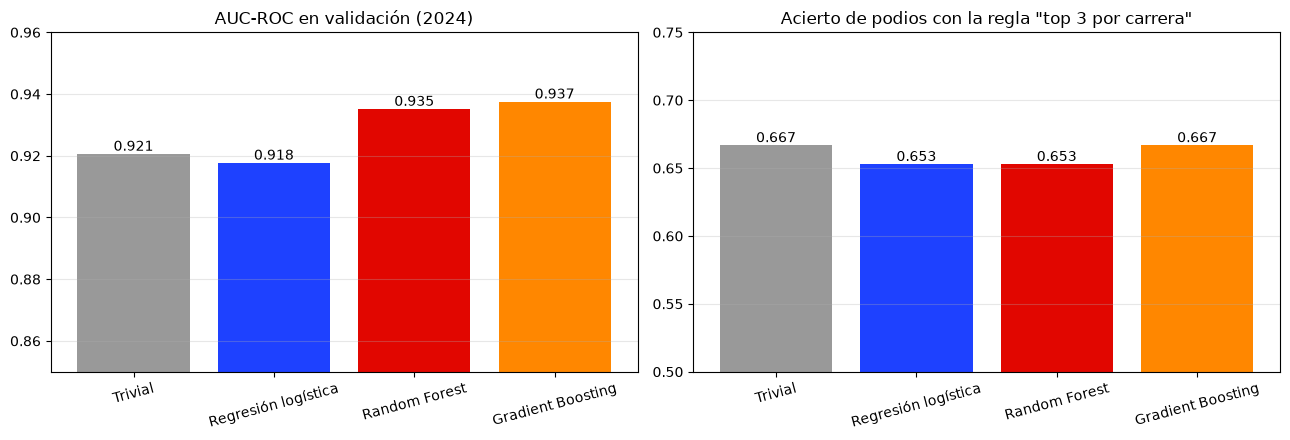

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
nombres = ['Trivial'] + list(modelos_val)
auc_val = [md.metricas_trivial(y_val, val)['AUC-ROC']] + [md.metricas(y_val, p)['AUC-ROC'] for p in probas_val.values()]
f1_val = [md.metricas_trivial(y_val, val)['F1']] + [md.metricas_top3(y_val, val, p)['F1'] for p in probas_val.values()]
colores = ['#999999', '#1E41FF', '#E10600', '#FF8700']

axes[0].bar(nombres, auc_val, color=colores)
axes[0].set_ylim(0.85, 0.96); axes[0].set_title('AUC-ROC en validación (2024)')
axes[1].bar(nombres, f1_val, color=colores)
axes[1].set_ylim(0.5, 0.75); axes[1].set_title('Acierto de podios con la regla "top 3 por carrera"')
for ax, valores in zip(axes, (auc_val, f1_val)):
    for i, v in enumerate(valores):
        ax.text(i, v, f'{v:.3f}', ha='center', va='bottom')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Conclusiones del día 24

- **Los modelos de árboles ordenan mejor:** el AUC en validación sube de 0,918 (logística) a ≈ 0,935-0,937, y también supera al trivial (0,921).
  Captan interacciones que la logística no ve.
- **Pero eligiendo exactamente 3 por carrera, el acierto de podios no mejora:** ≈ 65-67 % para todos, igual que el trivial.
  De 72 podios en 2024, la diferencia entre modelos es de 1 o 2 podios: **está dentro del ruido** (24 carreras es una muestra pequeña).
- Dicho de otra forma: el modelo ordena mejor a los pilotos *de la mitad de la parrilla* (quién tiene más probabilidad), pero los
  3 primeros candidatos son casi siempre los mismos que el trivial. La ganancia está en la calidad de las probabilidades, no en cambiar el podio predicho.
- **Gradient Boosting y Random Forest rinden igual.** El Random Forest queda algo mejor en la CV temporal (0,931 frente a 0,926) y el Gradient Boosting algo mejor en
  validación (0,937 frente a 0,935): diferencias de milésimas, dentro del ruido. El Gradient Boosting eligió una configuración muy conservadora
  (aprendizaje lento, `min_samples_leaf = 65`, `l2_regularization ≈ 7`), señal de que los datos son pequeños y ruidosos y de que conviene que el modelo no se ajuste a detalles.
- **El óptimo es plano:** las 5 mejores combinaciones de cada búsqueda difieren en menos de 0,002 de AUC. Los hiperparámetros apenas importan; lo que aporta es el tipo de modelo.

**Supuestos y limitaciones**
- Solo 2.500 filas de entrenamiento y ~15 % de positivos (~375 podios): poco para modelos complejos; por eso eligen los modelos más regularizados.
- La CV temporal asume que carreras antiguas (2018-2021, otro reglamento) siguen siendo informativas para 2024+.
- Elegir el mejor modelo con 24 carreras de validación tiene mucha varianza: diferencias pequeñas no son concluyentes.
- No se afinó el umbral de decisión (la regla "top 3" lo evita al aprovechar que siempre hay 3 podios).

---
## Día 25 · Interpretación y análisis de errores

Un modelo que no se puede explicar es difícil de defender en una entrevista. Dos preguntas:
1. **¿Qué variables usa de verdad el modelo?** → *permutation importance*.
2. **¿Cuándo y por qué se equivoca?** → análisis de errores (lluvia, abandonos, sorpresas).

Analizo el **Gradient Boosting** (mejor AUC en validación). Todo el análisis es sobre **2024 (validación)**, de modo que el test de 2025 sigue sin tocarse.

### Permutation importance

Idea: tomo el conjunto de validación, **barajo al azar una sola columna** (rompiendo su relación con el podio) y mido cuánto cae el AUC.
Si cae mucho, el modelo dependía de esa variable; si no cae, la ignoraba.

Ventajas frente a la importancia interna de un Random Forest (basada en impurity): se calcula sobre datos **no vistos**, vale para cualquier modelo y
no favorece a las variables con muchos valores distintos. Se repite 30 veces para tener una desviación.

**Cuidado:** con variables correlacionadas (puntos del piloto y del equipo, r ≈ 0,95) la importancia se *reparte* o se infravalora: si barajo una, el modelo
todavía puede apoyarse en la otra.

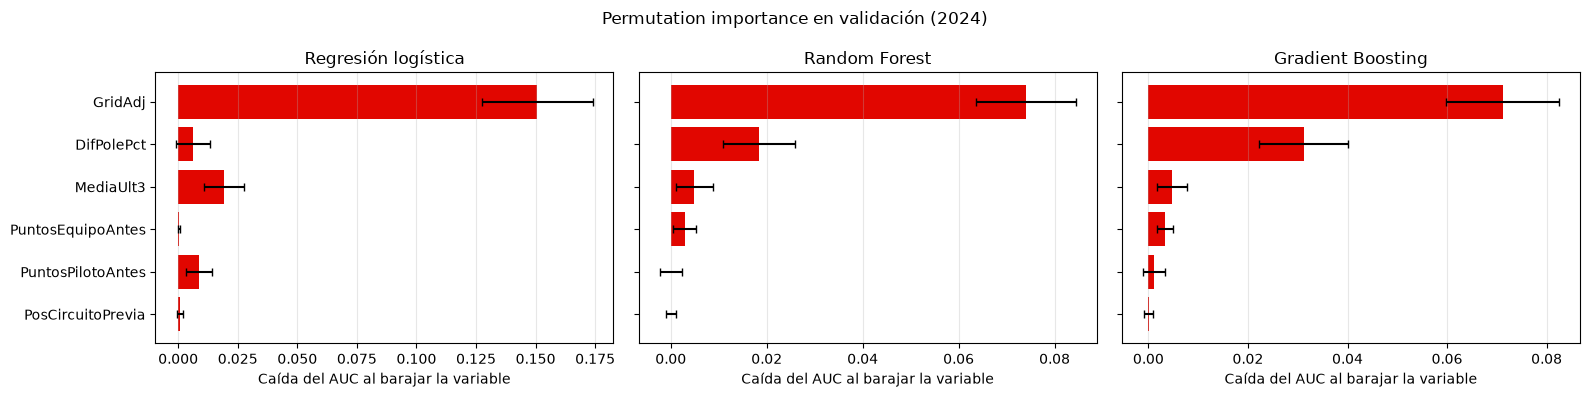

,media,sd
GridAdj,0.0712,0.0114
DifPolePct,0.0312,0.0089
MediaUlt3,0.0047,0.0030
PuntosEquipoAntes,0.0033,0.0017
PuntosPilotoAntes,0.0011,0.0022
PosCircuitoPrevia,0.0000,0.0009


In [22]:
from sklearn.inspection import permutation_importance

modelos_imp = {'Regresión logística': logit, 'Random Forest': rf, 'Gradient Boosting': hgb}
importancias = {}
for nombre, m in modelos_imp.items():
    r = permutation_importance(m, X_val, y_val, scoring='roc_auc', n_repeats=30, random_state=md.SEMILLA)
    importancias[nombre] = pd.DataFrame({'media': r.importances_mean, 'sd': r.importances_std}, index=ft.FEATURES)

imp_hgb = importancias['Gradient Boosting'].sort_values('media', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
orden = imp_hgb.index[::-1]
for ax, (nombre, imp) in zip(axes, importancias.items()):
    ax.barh(orden, imp.loc[orden, 'media'], xerr=imp.loc[orden, 'sd'], color='#E10600', capsize=3)
    ax.set_title(nombre)
    ax.set_xlabel('Caída del AUC al barajar la variable')
    ax.grid(alpha=0.3, axis='x')
plt.suptitle('Permutation importance en validación (2024)')
plt.tight_layout()
plt.show()
imp_hgb.round(4)

**Lectura**
- Los tres modelos coinciden: **`GridAdj` (la posición de salida) es, con diferencia, la variable más importante** (al barajarla el AUC cae ≈ 0,07), seguida de **`DifPolePct`** (≈ 0,03).
  Es coherente con la regresión logística y con el hecho de que el modelo trivial rinda tan bien.
- `MediaUlt3` aporta algo (milésimas). **`PuntosPilotoAntes`, `PuntosEquipoAntes` y `PosCircuitoPrevia` casi no aportan** una vez conocidas parrilla y ritmo en clasificación:
  la parrilla ya resume la fuerza del coche en ese fin de semana, y la clasificación es una medida mucho más fresca que los puntos acumulados.
- Las variables "de contexto" (puntos, historial) podrían simplificarse sin perder casi nada. No las quito: la importancia por permutación mide el efecto *marginal*, y con correlaciones podría infravalorarlas.

### Análisis de errores

Con la regla "los 3 con más probabilidad de cada carrera" hay tres tipos de resultado por piloto:
- **Acierto:** predicho y en el podio.
- **Falso positivo (FP):** predicho, pero no acabó en el podio. ¿Por qué? ¿Abandonó o solo acabó cerca?
- **Falso negativo (FN):** acabó en el podio y no lo predijimos. ¿Quién fue la sorpresa?

Para la lluvia uso la meteorología de 2024 (`weather_2024.parquet`): una carrera es **mojada** si en ≥ 10 % de las mediciones se registró lluvia
(Canadá, Gran Bretaña y São Paulo).

In [23]:
v = val.copy()
v['proba'] = probas_val['Gradient Boosting']
v['PredTop3'] = md.predecir_top3(v, v['proba'])
v['Abandono'] = md.abandono(v)

meteo = pd.read_parquet('data/raw/weather_2024.parquet')
frac_lluvia = meteo.groupby('Round')['Rainfall'].mean()
v['Mojada'] = v['Round'].map(frac_lluvia).ge(0.10)

v['Acierto'] = (v['PredTop3'] == 1) & (v[ft.TARGET] == 1)
v['FP'] = (v['PredTop3'] == 1) & (v[ft.TARGET] == 0)
v['FN'] = (v['PredTop3'] == 0) & (v[ft.TARGET] == 1)

carreras = (v.groupby(['Round', 'Event'])
            .agg(Mojada=('Mojada', 'first'), Aciertos=('Acierto', 'sum'),
                 AbandonosEntrePredichos=('Abandono', lambda s: int((s & v.loc[s.index, 'PredTop3'].eq(1)).sum())))
            .reset_index())
carreras['Aciertos'] = carreras['Aciertos'].astype(int)

print('Podios acertados por carrera (de 3):', carreras['Aciertos'].value_counts().sort_index().to_dict())
carreras.sort_values('Aciertos').head(6)

Podios acertados por carrera (de 3): {0: 1, 1: 3, 2: 15, 3: 5}


,Round,Event,Mojada,Aciertos,AbandonosEntrePredichos
20,21,São Paulo Grand Prix,True,0,0
0,1,Bahrain Grand Prix,False,1,0
10,11,Austrian Grand Prix,False,1,0
22,23,Qatar Grand Prix,False,1,0
21,22,Las Vegas Grand Prix,False,2,0
19,20,Mexico City Grand Prix,False,2,0


### ¿Falla más con lluvia?

In [24]:
lluvia = carreras.groupby('Mojada')['Aciertos'].agg(['mean', 'count']).rename(
    index={False: 'Seca', True: 'Mojada'}, columns={'mean': 'Podios acertados (de 3)', 'count': 'Carreras'}).round(2)
display(lluvia)
display(carreras[carreras['Mojada']][['Event', 'Aciertos']])

fn_mojada = v[v['Mojada'] & v['FN']][['Event', 'Abbreviation', 'GridAdj', 'Position', 'proba']].round(2)
display(fn_mojada)

,Podios acertados (de 3),Carreras
Mojada,,
Seca,2.05,21
Mojada,1.67,3


,Event,Aciertos
8,Canadian Grand Prix,3
11,British Grand Prix,2
20,São Paulo Grand Prix,0


,Event,Abbreviation,GridAdj,Position,proba
2720,British Grand Prix,VER,4,2,0.85
2899,São Paulo Grand Prix,VER,17,1,0.39
2900,São Paulo Grand Prix,OCO,4,2,0.41
2901,São Paulo Grand Prix,GAS,13,3,0.06


**Lluvia.** En las 3 carreras mojadas de 2024 se acierta una media de **≈ 1,7 podios de 3**, frente a **≈ 2,0** en seco: ligeramente peor, pero con **solo 3 carreras
mojadas no hay base estadística para afirmarlo** (una carrera más o menos cambia la media).
Lo que sí es cualitativamente llamativo es São Paulo 2024: el modelo no pudo anticipar un podio con Verstappen (salió 17º y ganó) y Gasly (salió 13º, podio),
con probabilidades de 0,39 y 0,06. La lluvia con bandera roja y cambios de neumáticos desordena la parrilla y nuestras variables solo conocen la parrilla.
**Limitación:** no tengo meteorología de 2018-2023 en este proyecto; ampliar la descarga de FastF1 permitiría repetir el análisis con muchas más carreras mojadas.

### ¿Falla más con abandonos?

Un abandono es imposible de ver en las variables previas (fallo mecánico, accidente), pero deja una huella clara:
si un piloto predicho se retira, esa carrera pierde un podio seguro. Para tener más muestra que 2024 uso además las **predicciones fuera de muestra**
del entrenamiento (2019-2023): cada carrera se predice con un modelo que solo había visto carreras anteriores.

In [25]:
mejor_hgb = busquedas['Gradient Boosting'].best_estimator_
oof = md.probabilidades_fuera_de_muestra(mejor_hgb, X_train, y_train, train)
t = train.assign(proba=oof).dropna(subset=['proba']).copy()
t['PredTop3'] = md.predecir_top3(t, t['proba'])
t['Abandono'] = md.abandono(t)


def causas_fp_fn(df):
    """Reparte los falsos positivos y negativos por causa."""
    fp = df[(df['PredTop3'] == 1) & (df[ft.TARGET] == 0)]
    fn = df[(df['PredTop3'] == 0) & (df[ft.TARGET] == 1)]
    causas_fp = pd.Series({
        'Abandonó / no clasificado': fp['Abandono'].sum(),
        'Acabó 4º-6º (cerca)': (~fp['Abandono'] & fp['Position'].between(4, 6)).sum(),
        'Acabó 7º o peor': (~fp['Abandono'] & (fp['Position'] >= 7)).sum()})
    causas_fn = pd.Series({
        'Salía 4º-6º': fn['GridAdj'].between(4, 6).sum(),
        'Salía 7º-10º': fn['GridAdj'].between(7, 10).sum(),
        'Salía 11º o peor': (fn['GridAdj'] >= 11).sum(),
        'Salía en el top 3 pero no lo predijimos': (fn['GridAdj'] <= 3).sum()})
    return causas_fp, causas_fn


fp_oof, fn_oof = causas_fp_fn(t)
fp_val, fn_val = causas_fp_fn(v)
display(pd.DataFrame({'2019-2023 (fuera de muestra)': fp_oof, '2024 (validación)': fp_val}).assign(
    **{'% 2019-2023': lambda d: (d.iloc[:, 0] / d.iloc[:, 0].sum() * 100).round(0)}))
display(pd.DataFrame({'2019-2023 (fuera de muestra)': fn_oof, '2024 (validación)': fn_val}).assign(
    **{'% 2019-2023': lambda d: (d.iloc[:, 0] / d.iloc[:, 0].sum() * 100).round(0)}))

abandono_predichos = t[t['PredTop3'] == 1]['Abandono'].mean()
print(f'Abandonos entre los pilotos predichos como podio (2019-2023): {abandono_predichos:.1%}  (tasa general: {t["Abandono"].mean():.1%})')
n_carreras = t.groupby(['Year', 'Round']).ngroups
perdidas = t[(t['PredTop3'] == 1) & t['Abandono']].groupby(['Year', 'Round']).size()
print(f'Carreras en las que al menos un piloto predicho abandona: {len(perdidas)} de {n_carreras} ({len(perdidas) / n_carreras:.0%})')

,2019-2023 (fuera de muestra),2024 (validación),% 2019-2023
Abandonó / no clasificado,26,2,27.0
Acabó 4º-6º (cerca),38,14,39.0
Acabó 7º o peor,33,8,34.0


,2019-2023 (fuera de muestra),2024 (validación),% 2019-2023
Salía 4º-6º,63,19,65.0
Salía 7º-10º,18,2,19.0
Salía 11º o peor,16,3,16.0
Salía en el top 3 pero no lo predijimos,0,0,0.0


Abandonos entre los pilotos predichos como podio (2019-2023): 8.7%  (tasa general: 12.8%)
Carreras en las que al menos un piloto predicho abandona: 25 de 100 (25%)


### Lo que revela el análisis

**Abandonos (falsos positivos).**
- En 2019-2023 el **27 %** de los falsos positivos son pilotos que abandonan (en 2024, 2 de 24): son podios imposibles de ver con datos previos.
  En **1 de cada 4 carreras** (25 de 100) al menos uno de los 3 pilotos predichos se retira.
- Aun así, los predichos abandonan menos que la media (8,7 % frente a 12,8 %): el modelo escoge a los delanteros, que tienen coches más fiables.
- El resto de falsos positivos se reparte entre pilotos que acaban **cerca del podio (4º-6º, ≈ 39 %)** y los que acaban 7º o peor (≈ 34 %): el rival o el compañero
  se llevó la plaza con una estrategia, un adelantamiento o un safety car.

**Falsos negativos (podios que no vimos venir).**
- **Dos tercios (≈ 65 %) salían 4º-6º.** Con solo 3 plazas, los 3 primeros de la parrilla acaparan la probabilidad, y los 4º-6º, con un coche casi igual,
  quedan justo por debajo. Es un error **estructural** de predecir con la parrilla: no hay información previa que diga cuál de ellos remontará.
- Las auténticas sorpresas (salir 11º o peor y subir al podio) son el ≈ 16 %. En 2024, 2 de las 3 fueron en São Paulo (lluvia y bandera roja); la tercera, Abu Dhabi (Leclerc, 19º en parrilla).

**Respuesta a la pregunta del plan:** el modelo falla **algo más en lluvia** (aunque solo hay 3 carreras mojadas y no es concluyente) y **cuando hay abandonos**
(en 1 de cada 4 carreras pierde algún podio por esa causa), pero el error más frecuente y sistemático es otro: **no saber cuál de los pilotos de las posiciones 4ª-6ª
acabará en el podio**.

**Siguiente paso posible (no implementado):** añadir variables de estrategia (compuesto de salida, probabilidad de safety car por circuito, ritmo en tandas largas de libres) mejoraría
precisamente los casos de 4º-6º, porque es la información que diferencia a los candidatos cercanos.

---
## Día 26 · Guardar el modelo y exportar predicciones

### Procedimiento (para no contaminar el test)

1. **Test (2025), por primera y única vez.** Reajusto cada modelo con sus mejores hiperparámetros usando todo lo anterior (2018-2024: entrenamiento + validación)
   y lo evalúo en 2025. La elección del mejor modelo ya está hecha con la validación; el test solo confirma cuánto vale.
2. **Modelo final.** Lo reajusto con 2018-2025 y lo guardo en `models/` para predecir 2026 ("en vivo").
3. **Predicciones.**
   - 2025: del modelo entrenado hasta 2024, es decir, *fuera de muestra*.
   - 2026: del modelo entrenado hasta 2025. Son carreras ya disputadas que el modelo no ha visto, así que también podemos comprobar si acierta.

In [26]:
hasta_2024 = datos[datos['Year'] <= 2024]
X_te, y_te = test[ft.FEATURES], test[ft.TARGET]

# Pipelines con los hiperparámetros elegidos en el día 24 (la regresión logística no tiene búsqueda)
base = {'Regresión logística': logit, 'Random Forest': rf, 'Gradient Boosting': hgb}
reajustados = {n: md.reajustar(m, hasta_2024, ft.FEATURES) for n, m in base.items()}
probas_test = {n: m.predict_proba(X_te)[:, 1] for n, m in reajustados.items()}

filas = []
for n in base:
    filas.append({'Modelo': n, 'Conjunto': 'Validación 2024',
                  **{k: v for k, v in md.metricas_top3(y_val, val, probas_val[n]).items() if k in ('AUC-ROC', 'F1')},
                  'F1 (umbral 0,5)': md.metricas(y_val, probas_val[n])['F1']})
    filas.append({'Modelo': n, 'Conjunto': 'Test 2025',
                  **{k: v for k, v in md.metricas_top3(y_te, test, probas_test[n]).items() if k in ('AUC-ROC', 'F1')},
                  'F1 (umbral 0,5)': md.metricas(y_te, probas_test[n])['F1']})
tv, tt = md.metricas_trivial(y_val, val), md.metricas_trivial(y_te, test)
filas.append({'Modelo': 'Trivial (top 3 parrilla)', 'Conjunto': 'Validación 2024', 'AUC-ROC': tv['AUC-ROC'], 'F1': tv['F1'], 'F1 (umbral 0,5)': tv['F1']})
filas.append({'Modelo': 'Trivial (top 3 parrilla)', 'Conjunto': 'Test 2025', 'AUC-ROC': tt['AUC-ROC'], 'F1': tt['F1'], 'F1 (umbral 0,5)': tt['F1']})

comparativa = (pd.DataFrame(filas).rename(columns={'F1': 'Acierto top 3 (=F1)'})
               .set_index(['Modelo', 'Conjunto']).round(3))
comparativa

Acierto top 3 (=F1)  AUC-ROC  \
Modelo                   Conjunto                                        
Regresión logística      Validación 2024                0.653    0.918   
                         Test 2025                      0.736    0.934   
Random Forest            Validación 2024                0.653    0.935   
                         Test 2025                      0.778    0.951   
Gradient Boosting        Validación 2024                0.667    0.937   
                         Test 2025                      0.750    0.951   
Trivial (top 3 parrilla) Validación 2024                0.667    0.921   
                         Test 2025                      0.750    0.930   

                                          F1 (umbral 0,5)  
Modelo                   Conjunto                          
Regresión logística      Validación 2024            0.606  
                         Test 2025                  0.635  
Random Forest            Validación 2024            0.654  
                         Test 2025                  0.663  
Gradient Boosting        Validación 2024            0.654  
                         Test 2025                  0.663  
Trivial (top 3 parrilla) Validación 2024            0.667  
                         Test 2025                  0.750

**Nota sobre la columna "Acierto top 3":** con 3 elegidos y 3 podios, precisión = recall = F1 = % de podios acertados.

### ¿La diferencia con el modelo trivial es real o ruido?

En 24 carreras, un podio más o menos cambia mucho la cifra. Para saber si el modelo supera de verdad al trivial comparo, **carrera a carrera**,
cuántos podios acierta cada uno (de 3) y calculo un intervalo de confianza de la diferencia media por **bootstrap sobre carreras**
(remuestreo de carreras completas, que es la unidad independiente real).

In [27]:
def aciertos_por_carrera(df, pred):
    t = df[['Year', 'Round']].copy()
    t['hit'] = (np.asarray(pred) == 1) & (df[ft.TARGET].to_numpy() == 1)
    return t.groupby(['Year', 'Round'])['hit'].sum()


def ic_diferencia(a, b, n=5000, semilla=md.SEMILLA):
    """Diferencia media (a - b) por carrera con IC 95 % por bootstrap sobre carreras."""
    d = (a - b).to_numpy()
    rng = np.random.default_rng(semilla)
    medias = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)


triv_val = aciertos_por_carrera(val, md.pred_trivial_parrilla(val))
triv_te = aciertos_por_carrera(test, md.pred_trivial_parrilla(test))
filas = []
for n in base:
    mv = aciertos_por_carrera(val, md.predecir_top3(val, probas_val[n]))
    mt = aciertos_por_carrera(test, md.predecir_top3(test, probas_test[n]))
    for conj, a, b in [('Validación 2024', mv, triv_val), ('Test 2025', mt, triv_te)]:
        dif, lo, hi = ic_diferencia(a, b)
        filas.append({'Modelo': n, 'Conjunto': conj, 'Podios/carrera modelo': a.mean(), 'Podios/carrera trivial': b.mean(),
                      'Diferencia': dif, 'IC 95 % inf': lo, 'IC 95 % sup': hi})
pd.DataFrame(filas).set_index(['Modelo', 'Conjunto']).round(2)

Podios/carrera modelo  \
Modelo              Conjunto                                 
Regresión logística Validación 2024                   1.96   
                    Test 2025                         2.21   
Random Forest       Validación 2024                   1.96   
                    Test 2025                         2.33   
Gradient Boosting   Validación 2024                   2.00   
                    Test 2025                         2.25   

                                     Podios/carrera trivial  Diferencia  \
Modelo              Conjunto                                              
Regresión logística Validación 2024                    2.00       -0.04   
                    Test 2025                          2.25       -0.04   
Random Forest       Validación 2024                    2.00       -0.04   
                    Test 2025                          2.25        0.08   
Gradient Boosting   Validación 2024                    2.00        0.00   
                    Test 2025                          2.25        0.00   

                                     IC 95 % inf  IC 95 % sup  
Modelo              Conjunto                                   
Regresión logística Validación 2024        -0.29         0.21  
                    Test 2025              -0.21         0.12  
Random Forest       Validación 2024        -0.12         0.00  
                    Test 2025               0.00         0.21  
Gradient Boosting   Validación 2024         0.00         0.00  
                    Test 2025               0.00         0.00

### Elegir y guardar el mejor modelo

Criterio fijado **antes de mirar el test**: mayor AUC-ROC en validación → **Gradient Boosting** (0,937). Lo reajusto con 2018-2025 y lo guardo con `joblib`,
junto a un JSON con sus metadatos (variables, hiperparámetros, años de entrenamiento y versión de scikit-learn, porque un modelo serializado solo es seguro de cargar con la misma versión).

In [28]:
hasta_2025 = datos[datos['Year'] <= 2025]
modelo_final = md.reajustar(hgb, hasta_2025, ft.FEATURES)

md.guardar_modelo(
    modelo_final, 'models/modelo_podio.joblib',
    {'modelo': 'HistGradientBoostingClassifier', 'variables': ft.FEATURES, 'objetivo': 'Podio (Position <= 3)',
     'entrenado_con': '2018-2025', 'hiperparametros': {k: float(v) if not isinstance(v, str) else v
                                                      for k, v in modelo_final.named_steps['hgb'].get_params().items()
                                                      if k in ('learning_rate', 'max_iter', 'max_depth', 'min_samples_leaf', 'l2_regularization')},
     'metricas_test_2025_modelo_hasta_2024': {'AUC-ROC': round(md.metricas(y_te, probas_test['Gradient Boosting'])['AUC-ROC'], 4),
                                              'acierto_top3': round(md.metricas_top3(y_te, test, probas_test['Gradient Boosting'])['F1'], 4)}})

# Comprobación: el modelo cargado de disco da exactamente las mismas probabilidades
recargado = md.cargar_modelo('models/modelo_podio.joblib')
assert np.allclose(recargado.predict_proba(vivo[ft.FEATURES]), modelo_final.predict_proba(vivo[ft.FEATURES]))
print('Modelo guardado y recargado correctamente:', os.listdir('models'))

Modelo guardado y recargado correctamente: ['modelo_podio.json', 'modelo_podio.joblib']


### Exportar las predicciones

Una fila por piloto y carrera. `Proba` es la probabilidad cruda del modelo; como se entrenó con `class_weight='balanced'` tiende a ser alta, así que añado
`ProbaNorm`, la misma probabilidad reescalada para que sume 3 en cada carrera (hay siempre 3 podios). `PredPodio = 1` marca a los 3 con más probabilidad.

In [29]:
pred_2025 = md.tabla_predicciones(test, probas_test['Gradient Boosting'], 'Test 2025 (modelo hasta 2024)', 'Gradient Boosting')
pred_2026 = md.tabla_predicciones(vivo, modelo_final.predict_proba(vivo[ft.FEATURES])[:, 1],
                                  'En vivo 2026 (modelo hasta 2025)', 'Gradient Boosting')
predicciones = pd.concat([pred_2025, pred_2026], ignore_index=True)
predicciones.to_csv('data/processed/predicciones_podio.csv', index=False)
comparativa.reset_index().to_csv('data/processed/comparativa_modelos.csv', index=False)

print(f'predicciones_podio.csv: {len(predicciones)} filas · {predicciones.groupby(["Year", "Round"]).ngroups} carreras')
ultima = pred_2026[pred_2026['Round'] == pred_2026['Round'].max()].sort_values('RankProba')
print('\nÚltima carrera disputada:', ultima['Event'].iloc[0], ultima['Date'].iloc[0])
ultima[['RankProba', 'Abbreviation', 'TeamName', 'GridAdj', 'Proba', 'ProbaNorm', 'PosicionReal']].head(6).round(2)

predicciones_podio.csv: 853 filas · 41 carreras

Última carrera disputada: Singapore Grand Prix 2026-10-11


,RankProba,Abbreviation,TeamName,GridAdj,Proba,ProbaNorm,PosicionReal
3810,1,VER,Red Bull,1,0.95,0.44,1
3811,2,LEC,Ferrari,2,0.93,0.43,2
3815,3,HAM,Ferrari,3,0.86,0.40,6
3812,4,ANT,Mercedes,4,0.84,0.39,3
3813,5,NOR,McLaren,5,0.60,0.27,4
3819,6,HAD,Red Bull,22,0.59,0.27,10


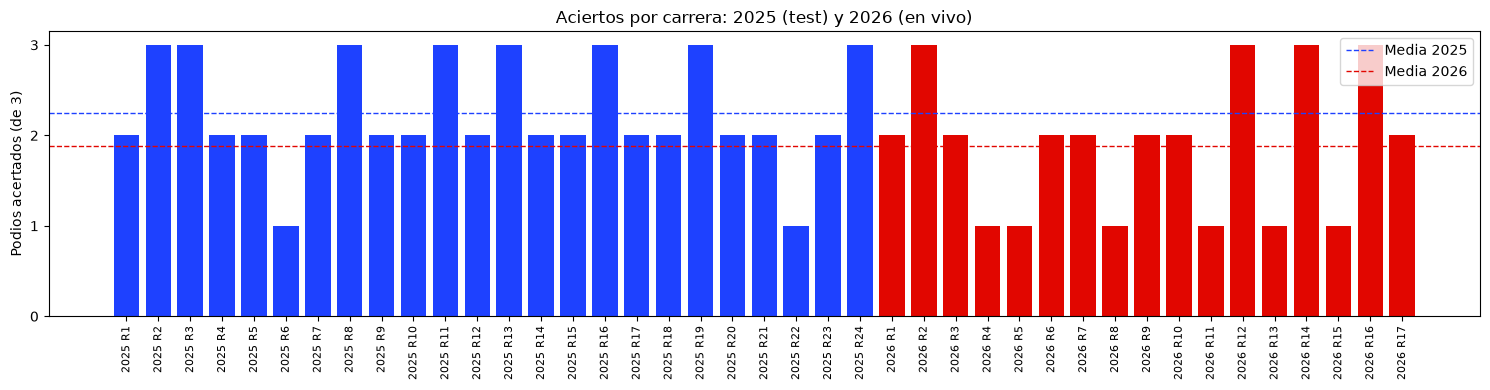

,Podios acertados/carrera,Carreras
Year,,
2025,2.25,24
2026,1.88,17


In [30]:
# Acierto por carrera y por año (podios acertados de 3)
hits = (predicciones.assign(hit=lambda d: (d['PredPodio'] == 1) & (d['PodioReal'] == 1))
        .groupby(['Year', 'Round', 'Event'])['hit'].sum().reset_index())
hits['Carrera'] = hits['Year'].astype(str) + ' R' + hits['Round'].astype(str)

fig, ax = plt.subplots(figsize=(15, 4))
colores = np.where(hits['Year'] == 2025, '#1E41FF', '#E10600')
ax.bar(hits['Carrera'], hits['hit'], color=colores)
ax.axhline(hits.groupby('Year')['hit'].mean().loc[2025], color='#1E41FF', ls='--', lw=1, label='Media 2025')
ax.axhline(hits.groupby('Year')['hit'].mean().loc[2026], color='#E10600', ls='--', lw=1, label='Media 2026')
ax.set_yticks([0, 1, 2, 3]); ax.set_ylabel('Podios acertados (de 3)')
ax.set_title('Aciertos por carrera: 2025 (test) y 2026 (en vivo)')
ax.tick_params(axis='x', rotation=90, labelsize=8)
ax.legend()
plt.tight_layout()
plt.show()
hits.groupby('Year')['hit'].agg(['mean', 'count']).round(2).rename(columns={'mean': 'Podios acertados/carrera', 'count': 'Carreras'})

### ¿Cuántas veces elige el modelo un podio distinto al del modelo trivial?

In [31]:
p = predicciones.copy()
p['Trivial'] = (p['GridAdj'] <= 3).astype(int)


def mismo_podio(g):
    return set(g.loc[g['PredPodio'] == 1, 'DriverId']) == set(g.loc[g['Trivial'] == 1, 'DriverId'])


iguales = p.groupby(['Year', 'Round'])[['PredPodio', 'Trivial', 'DriverId']].apply(mismo_podio)
resumen_iguales = pd.DataFrame({
    'Carreras': iguales.groupby('Year').size(),
    'Mismo top 3 que el trivial': iguales.groupby('Year').sum(),
    'Podios/carrera modelo': hits.groupby('Year')['hit'].mean().round(2),
    'Podios/carrera trivial': p.assign(h=(p['Trivial'] == 1) & (p['PodioReal'] == 1)).groupby(['Year', 'Round'])['h'].sum().groupby('Year').mean().round(2),
})
resumen_iguales

,Carreras,Mismo top 3 que el trivial,Podios/carrera modelo,Podios/carrera trivial
Year,,,,
2025,24,24,2.25,2.25
2026,17,17,1.88,1.88


### Conclusiones de la Fase 4

1. **El modelo ordena mejor, pero el podio que predice es el mismo que el del modelo trivial.** En 2025 y 2026 (41 carreras), el top 3 del Gradient Boosting
   coincide *exactamente* con los 3 primeros de la parrilla en **todas** las carreras. Por eso su acierto (2,25 podios de 3 en 2025; 1,88 en 2026) es idéntico al trivial.
   Donde sí aporta es en el AUC (0,951 frente a 0,930 en test) y en las probabilidades **del resto de la parrilla** (¿quién es el 4º o el 5º candidato?),
   que es lo que usa el dashboard.
2. **Es un resultado honesto sobre el problema, no un fallo del código.** La posición de salida y la distancia a la pole concentran casi toda la señal
   (permutation importance), y con solo variables previas a la carrera el podio "obvio" es el de la parrilla. Lo que no es obvio (adelantamientos, estrategia, safety car,
   abandonos) no está en estas variables.
3. **Mejor modelo guardado:** Gradient Boosting, elegido por AUC en validación (criterio fijado antes de ver el test). Random Forest rinde igual dentro del ruido.
4. **2026 acierta menos (1,88 frente a 2,25).** Con 17 carreras no es concluyente, pero encaja con el cambio de reglamento de 2026 (los patrones de 2018-2025 pueden no
   trasladarse) y con un coche más en la parrilla (22 coches, y el modelo solo vio parrillas de hasta 20-21).

**Supuestos y limitaciones del modelo final**
- Probabilidades **no calibradas** (por `class_weight='balanced'`): sirven para ordenar; `ProbaNorm` las reescala para sumar 3 por carrera, pero sigue siendo un ajuste simple.
- El modelo de 2026 no se actualiza carrera a carrera: está entrenado con 2018-2025.
- Hay fuerte dependencia entre filas de una misma carrera (comparten pista, clima, safety car); las métricas por fila son optimistas y por eso comparé también por carrera.
- Muestras pequeñas: 24 carreras por año. Diferencias de 1-2 podios no son concluyentes.
- Faltan variables que sí importan: estrategia, ritmo de carrera en libres, meteorología pronosticada, penalizaciones, fiabilidad por componente.